# El arte del lúpulo: datos, estilos y valoraciones de las cervezas.
### Análisis exploratorio de datos (EDA).

Los datos proceden del conjunto de datos [Beer Reviews de Kaggle](https://www.kaggle.com/datasets/rdoume/beerreviews), que contiene aproximadamente 1,59 millones de reseñas de cervezas. 
Cada fila representa una reseña individual, por lo que una misma cerveza puede aparecer en varias filas.

El objetivo del proyecto es analizar qué características se relacionan con las valoraciones de las cervezas, identificar los estilos mejor valorados y estudiar si existe una relación entre la graduación alcohólica y la puntuación general. 

Los resultados servirán como base para desarrollar una aplicación que permita explorar y recomendar cervezas según las preferencias del usuario.

## 0. Comprobación

In [42]:
import pandas as pd
import matplotlib

print("Todo listo")

Todo listo


## 1. ¿Qué tengo?

Empieza por ver qué hay en la tabla.

**1.1** Carga tu CSV de la carpeta datos en una tabla con un nombre que diga qué es (como pisos o titanic) y enseña las primeras filas.

In [43]:
cervezas = pd.read_csv("datos/beer_reviews.csv") # cargamos el archivo cvs en un dataframe de pandas, y nombramos la variable donde se guardan los datos.

cervezas.head() # se muestran las cinco primeras filas

,brewery_id,brewery_name,review_time,review_overall,review_aroma,review_appearance,review_profilename,beer_style,review_palate,review_taste,beer_name,beer_abv,beer_beerid
0,10325,Vecchio Birraio,1234817823,1.5,2.0,2.5,stcules,Hefeweizen,1.5,1.5,Sausa Weizen,5.0,47986
1,10325,Vecchio Birraio,1235915097,3.0,2.5,3.0,stcules,English Strong Ale,3.0,3.0,Red Moon,6.2,48213
2,10325,Vecchio Birraio,1235916604,3.0,2.5,3.0,stcules,Foreign / Export Stout,3.0,3.0,Black Horse Black Beer,6.5,48215
3,10325,Vecchio Birraio,1234725145,3.0,3.0,3.5,stcules,German Pilsener,2.5,3.0,Sausa Pils,5.0,47969
4,1075,Caldera Brewing Company,1293735206,4.0,4.5,4.0,johnmichaelsen,American Double / Imperial IPA,4.0,4.5,Cauldron DIPA,7.7,64883


**1.2** ¿Cuántas filas y columnas tiene?

In [44]:
cervezas.shape

(1586614, 13)

**1.3** Mira el info(). ¿De qué tipo es cada columna? ¿Cuáles tienen huecos?

In [45]:
cervezas.info()

# El conjunto de datos original contiene 1.586.614 registros y 13 columnas de tipos enteros, decimales y texto. 
# Las columnas con valores ausentes son `brewery_name`, `review_profilename` y `beer_abv`, siendo esta última la que presenta más ausencias, con 67.785.
# La tabla ocupa aproximadamente 265 MB en memoria.

<class 'pandas.DataFrame'>
RangeIndex: 1586614 entries, 0 to 1586613
Data columns (total 13 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   brewery_id          1586614 non-null  int64  
 1   brewery_name        1586599 non-null  str    
 2   review_time         1586614 non-null  int64  
 3   review_overall      1586614 non-null  float64
 4   review_aroma        1586614 non-null  float64
 5   review_appearance   1586614 non-null  float64
 6   review_profilename  1586266 non-null  str    
 7   beer_style          1586614 non-null  str    
 8   review_palate       1586614 non-null  float64
 9   review_taste        1586614 non-null  float64
 10  beer_name           1586614 non-null  str    
 11  beer_abv            1518829 non-null  float64
 12  beer_beerid         1586614 non-null  int64  
dtypes: float64(6), int64(3), str(4)
memory usage: 265.0 MB


**1.4** Quédate con las columnas que te sirven para tu pregunta, o quita las que sobran.

In [46]:
cervezas = cervezas.drop(columns=["brewery_id", "review_profilename", "review_time"])   # eliminamos esas tres columnas.

cervezas.columns    # comprobamos que se ha eliminado

Index(['brewery_name', 'review_overall', 'review_aroma', 'review_appearance',
       'beer_style', 'review_palate', 'review_taste', 'beer_name', 'beer_abv',
       'beer_beerid'],
      dtype='str')

**1.5** Si los nombres de las columnas están en inglés o son raros, ponles nombres en español.

In [47]:
cervezas.columns = ["cervecera", "rating", "rating_aroma", "rating_aspecto", "estilo_cerveza", "rating_boca", "rating_sabor", "cerveza", "graduacion", "id_cerveza"]
cervezas.columns


Index(['cervecera', 'rating', 'rating_aroma', 'rating_aspecto',
       'estilo_cerveza', 'rating_boca', 'rating_sabor', 'cerveza',
       'graduacion', 'id_cerveza'],
      dtype='str')

Lo que he visto y lo que he decidido:

El conjunto de datos contiene reseñas de cervezas realizadas por diferentes usuarios. Cada fila representa una reseña individual, en la que se valoran aspectos como la puntuación general, el aroma, el aspecto, el sabor y la sensación en boca.

Tras revisar las columnas, he conservado las que pueden ser útiles para analizar las valoraciones y encontrar patrones que ayuden a recomendar cervezas, y he eliminado "brewery_id", "review_profilename", "review_time", que no son datos útiles para nuestras consultas.

Por último, he cambiado los nombres de las columnas al español para facilitar su comprensión y trabajar con ellas de forma más clara durante el análisis.

## 2. ¿Qué me falta?

Cuenta lo que falta y decide qué haces con cada columna.

**2.1** Cuenta los huecos de cada columna.

In [48]:
cervezas.isna().sum()   

# .isna() comprueba los valores ausentes y devuelve: True si falta dato; False si existe.
# .sum() cuenta los valores ausentes de cada columna directamente.

# hay 15 filas en "cervecera" sin datos y 67.785 en "graduación".

cervecera            15
rating                0
rating_aroma          0
rating_aspecto        0
estilo_cerveza        0
rating_boca           0
rating_sabor          0
cerveza               0
graduacion        67785
id_cerveza            0
dtype: int64

**2.2** Calcula el porcentaje de huecos de cada columna.

In [49]:
porcentaje = cervezas.isna().sum() / len(cervezas) * 100    # con len() obtenemos el número total de filas
porcentaje.round(2) # para redondear a dos decimales

cervecera         0.00
rating            0.00
rating_aroma      0.00
rating_aspecto    0.00
estilo_cerveza    0.00
rating_boca       0.00
rating_sabor      0.00
cerveza           0.00
graduacion        4.27
id_cerveza        0.00
dtype: float64

**2.3** Decide qué haces con cada columna que tenga huecos: quitar la columna, quitar esas filas o rellenarlos. Hazlo.

In [50]:
cervezas = cervezas.dropna(subset=["graduacion"])
cervezas.shape

# La columna `graduacion` contiene un 4,27 % de valores ausentes. 
# He decidido eliminar las filas que no tienen este dato, ya que no puedo conocer la graduación alcohólica de esas cervezas y no quiero inventar información.
# El resto de las columnas no presenta valores ausentes o son pocos, por lo que no es necesario realizar ninguna modificación en ellas.

(1518829, 10)

**2.4** Comprueba que ya no quedan huecos, o que los que quedan los dejas a propósito.

In [51]:
cervezas.isna().sum()   # se han eliminado úncamente los valores desconocidos de graduación.

cervecera         15
rating             0
rating_aroma       0
rating_aspecto     0
estilo_cerveza     0
rating_boca        0
rating_sabor       0
cerveza            0
graduacion         0
id_cerveza         0
dtype: int64

**2.5** Mira con value_counts las columnas de texto. ¿Hay algún hueco disfrazado, como "Unknown", "-" o "N/A"?

In [52]:
# Elegimos tres columnas que contienen información de texto que identifica las cervezas y permite su clasificación. Value_counts() cuenta las veces que aparece el valor.

print(cervezas["cervecera"].value_counts())
print(cervezas["estilo_cerveza"].value_counts())
print(cervezas["cerveza"].value_counts())

#  En los resultados obtenidos no se aprecian valores ausentes disfrazados, aunque sería necesario revisar todos los valores para confirmarlo.

cervecera
Boston Beer Company (Samuel Adams)    38812
Dogfish Head Brewery                  33800
Stone Brewing Co.                     33022
Sierra Nevada Brewing Co.             28637
Bell's Brewery, Inc.                  24975
                                      ...  
Brasserie Du Corsaire                     1
Rascal Creek Brewing Co.                  1
Ludwig Ehrnsperger Gansbrauerei           1
Junction Craft Brewing                    1
Brauerei Lasser GmbH                      1
Name: count, Length: 5155, dtype: int64
estilo_cerveza
American IPA                        113164
American Double / Imperial IPA       85124
American Pale Ale (APA)              58081
Russian Imperial Stout               53432
American Double / Imperial Stout     50146
                                     ...  
English Pale Mild Ale                  649
Faro                                   609
Roggenbier                             395
Happoshu                               237
Kvass                

Lo que he visto y lo que he decidido:

He revisado la estructura del conjunto de datos, he eliminado tres columnas que no necesito y he traducido los nombres de las columnas al español. 
También he eliminado las filas que no tenían datos de graduación alcohólica. 
Por último, he comprobado los valores de las cerveceras, los estilos y los nombres de las cervezas, sin observar valores ausentes disfrazados en los resultados visibles.

## 3. ¿Hay filas repetidas?

Comprueba si hay algo contado dos veces.

**3.1** ¿Cuántas filas repetidas hay?

In [53]:
print("Filas repetidas:", cervezas.duplicated().sum())

Filas repetidas: 556374


**3.2** Si tienes una columna que identifica cada fila (un id, un nombre), ¿hay algún valor repetido?

In [54]:
# .duplicated() identifica los nombres que ya han aparecido anteriormente.
# .sum() cuenta cuántos nombres están repetidos.

print("Nombres de cervezas repetidos:", cervezas["cerveza"].duplicated().sum())

Nombres de cervezas repetidos: 1474744


**3.3** Decide si las quitas, y hazlo. Si no son la misma fila, no se quitan.

In [55]:
# Comprobamos cuántas filas están completamente duplicadas:

print("Filas repetidas:", cervezas.duplicated().sum())

# las mantenemos, ya que son reseñas distintas que simplemente coindicen.

Filas repetidas: 556374


In [56]:
# Para comprobar si las filas son idénticas.

cervezas_original = pd.read_csv("datos/beer_reviews.csv")

print("Filas duplicadas en el CSV original:", cervezas_original.duplicated().sum())

# Esto confirma que las 556.374 filas que aparecían como duplicadas en cervezas no eran filas completamente idénticas en el conjunto de datos original. 
# Al eliminar review_time y review_profilename, algunas reseñas distintas pasaron a tener los mismos valores en las columnas restantes.


Filas duplicadas en el CSV original: 0


Lo que he visto y lo que he decidido:

He observado que hay muchos nombres de cervezas repetidos, algo normal porque una cerveza puede recibir varias reseñas.

Aunque aparecen 556.374 filas duplicadas tras eliminar algunas columnas, he comprobado que el CSV original no tiene duplicados exactos, por lo que he decidido no eliminar esas filas, ya que pueden ser reseñas diferentes y contienen información útil para el análisis.

## 4. ¿Cómo son los números?

Mira los números con el describe, la media, la mediana y un histograma.

**4.1** Haz el describe. ¿Qué te llama la atención?

In [57]:
# Seleccionamos las columnas numéricas relevantes para analizar las valoraciones y la graduación.

cervezas[["rating", "rating_aroma", "rating_aspecto", "rating_boca", "rating_sabor", "graduacion"]].describe().round(2) # para obtener un resumen estadístico de las columnas numéricas de un conjunto de datos.

# Destaca que la graduación alcohólica media es del 7,04 %, con un máximo del 57,7 %, un valor que investigaremos en el punto 5 para comprobar si es correcto.
# También que la valoración general media es de 3,82 sobre 5 y que la mediana es 4, lo que indica que las puntuaciones tienden a ser altas.

,rating,rating_aroma,rating_aspecto,rating_boca,rating_sabor,graduacion
count,1518829.00,1518829.00,1518829.00,1518829.00,1518829.00,1518829.00
mean,3.82,3.75,3.85,3.75,3.80,7.04
std,0.72,0.70,0.61,0.68,0.73,2.32
min,0.00,1.00,0.00,1.00,1.00,0.01
25%,3.50,3.50,3.50,3.50,3.50,5.20
50%,4.00,4.00,4.00,4.00,4.00,6.50
75%,4.50,4.00,4.00,4.00,4.50,8.50
max,5.00,5.00,5.00,5.00,5.00,57.70


**4.2** Saca la media y la mediana de la columna de números más importante para tu pregunta. ¿Se parecen?

In [58]:
print("Valoración media:", round(cervezas["rating"].mean(), 2)) # la media
print("Valoración mediana:", round(cervezas["rating"].median(), 2)) # la mediana

# Se ha seleccionado rating como la variable más importnate del proyecto.
# La media y la mediana son muy parecidas, así que ambas apuntan a que las cervezas reciben valoraciones generalmente altas.

Valoración media: 3.82
Valoración mediana: 4.0


**4.3** Dibuja su histograma.

<Axes: title={'center': 'Distribución de las valoraciones de las cervezas'}, ylabel='Frequency'>

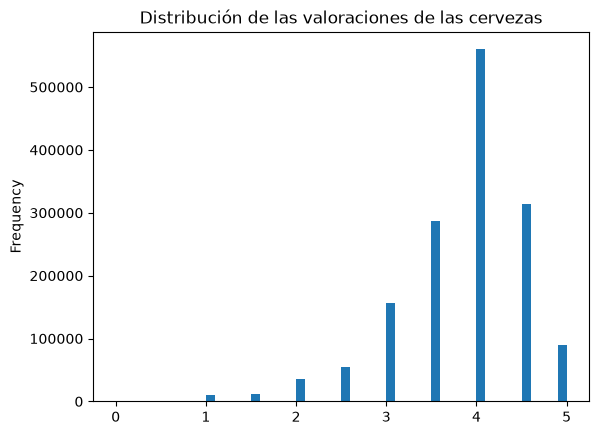

In [59]:
cervezas["rating"].plot(kind="hist", bins=50, title="Distribución de las valoraciones de las cervezas")

# .plot(kind="hist"): dibujamos un histograma.
# bins=50: dividimos los valores en 50 intervalos.

**4.4** Haz lo mismo con otra columna de números.

In [60]:
print("Graduación media:", round(cervezas["graduacion"].mean(), 2))
print("Graduación mediana:", round(cervezas["graduacion"].median(), 2))

# La media (7,04 %) es superior a la mediana (6,5 %). Esto puede indicar que algunas cervezas con graduaciones elevadas están aumentando la media.

Graduación media: 7.04
Graduación mediana: 6.5


<Axes: title={'center': 'Distribución de la graduación de las cervezas'}, ylabel='Frequency'>

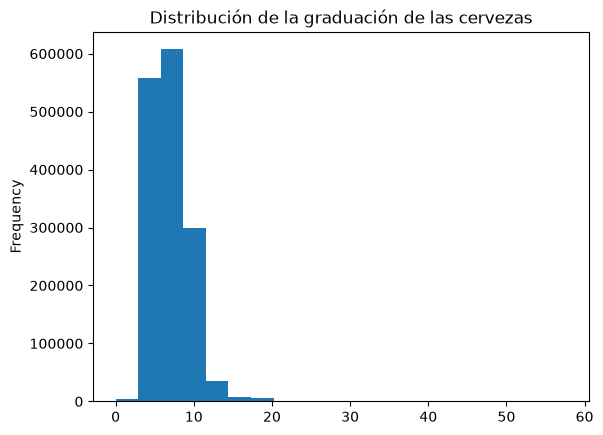

In [61]:
cervezas["graduacion"].plot(kind="hist", bins=20, title="Distribución de la graduación de las cervezas")

# El histograma apoya esta teoría: la mayoría de los registros se concentra en graduaciones relativamente bajas, mientras que hay unos pocos valores mucho más altos.

Lo que he visto y lo que he decidido:

El análisis estadístico muestra que las valoraciones de las cervezas son generalmente altas, con una puntuación media de 3,82 sobre 5. 
La graduación presenta una media del 7,04 % y una mediana del 6,5 %, lo que sugiere una distribución sesgada hacia valores más elevados. 
El histograma confirma la concentración de registros en graduaciones moderadas, aunque se observan valores extremos que requieren una revisión antes de determinar su validez. Estos resultados establecen una referencia inicial para el análisis posterior de los valores atípicos y de la posible relación entre graduación y valoración.

## 5. ¿Hay algo raro?

Busca los valores extremos y decide si son errores o casos reales.

**5.1** Enseña las 5 filas con el valor más alto de tu columna principal.

In [62]:
cervezas.drop_duplicates().sort_values("rating", ascending=False).head()

# drop_duplicates(): excluye las filas completamente duplicadas, sin modificar el DataFrame original.
# sort_values("rating"): ordena los registros por valoración.
# ascending=False: los ordena de mayor a menor.

# De esta forma examinamos los registros con las valoraciones más altas sin que los duplicados exactos ocupen varias posiciones.

,cervecera,rating,rating_aroma,rating_aspecto,estilo_cerveza,rating_boca,rating_sabor,cerveza,graduacion,id_cerveza
31,Caldera Brewing Company,5.0,4.5,4.0,Rauchbier,4.0,5.0,Rauch Ür Bock,7.4,58046
1205829,Mississippi Brewing Co.,5.0,4.5,4.0,Black & Tan,4.5,5.0,Mississippi Mud Black & Tan,5.0,1741
73,Caldera Brewing Company,5.0,4.0,4.5,American Pale Ale (APA),4.5,4.0,Caldera Pale Ale,5.5,25414
1586613,The Defiant Brewing Company,5.0,4.5,4.5,Pumpkin Ale,4.5,4.5,The Horseman's Ale,5.2,33061
1586579,The Defiant Brewing Company,5.0,4.5,4.0,Irish Dry Stout,4.5,4.5,O'Defiant Stout,5.5,36388


**5.2** Y las 5 con el más bajo. ¿Hay ceros o valores imposibles?

In [63]:
# De nuevo, excluimos los duplicados:

cervezas.drop_duplicates().sort_values("rating").head()

# El cero podría representar una valoración real muy negativa o una puntuación que se utilizó para indicar que no se valoró la cerveza.
# No son valores fuera de lo previsto. Las cinco filas tienen una valoración general (rating) de 0, pero las valoraciones de otras características son distintas de cero.

,cervecera,rating,rating_aroma,rating_aspecto,estilo_cerveza,rating_boca,rating_sabor,cerveza,graduacion,id_cerveza
39648,Desert Edge Brewery,0.0,4.0,0.0,Irish Dry Stout,2.0,2.0,Latter Days Stout,4.0,3804
39667,Desert Edge Brewery,0.0,3.0,0.0,American Pale Ale (APA),2.0,2.0,Utah Pale Ale,4.0,3810
653706,Red Rock Brewing Company,0.0,3.0,0.0,American Amber / Red Ale,2.5,3.5,Red Rock Amber Ale,4.0,3787
653695,Red Rock Brewing Company,0.0,2.0,0.0,Hefeweizen,2.5,2.0,Red Rock Bavarian Weiss,4.0,3788
653740,Red Rock Brewing Company,0.0,2.0,0.0,Dunkelweizen,2.5,2.0,Red Rock Dunkel Weizen,4.0,3786


**5.3** Haz el diagrama de caja de esa columna.

<Axes: title={'center': 'Distribución de las valoraciones de las cervezas'}>

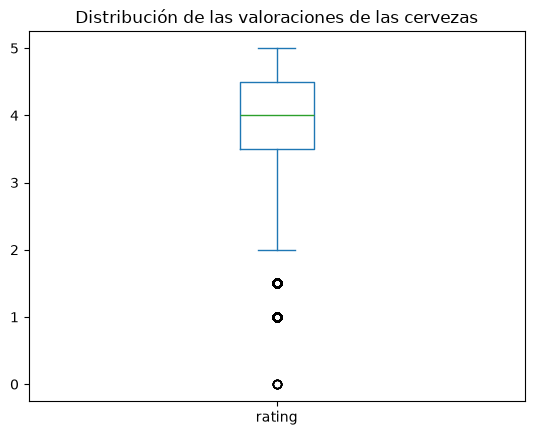

In [64]:
# El objetivo es visualizar la distribución de las valoraciones y detectar posibles valores atípicos.

cervezas["rating"].plot(kind="box", title="Distribución de las valoraciones de las cervezas")

# muestra que las valoraciones se concentran en la parte alta de la escala.
# Los valores inferiores a 2 aparecen como posibles valores atípicos, incluidos los ceros que hemos detectado en el apartado anterior.

**5.4** Decide qué haces con cada valor raro: si es un error, corrígelo o quítalo; si es real, se queda.

In [65]:
# Los ceros de rating aparecen junto a otras puntuaciones distintas de cero por lo que no parecen atípicos. No los sustituiré ni eliminaré.

# Las opivaloracionesniones bajas también se mantienen porque son opiniones de los usuarios.

Lo que he visto y lo que he decidido:

Las valoraciones generales oscilan entre 0 y 5, con algunos valores bajos que aparecen como posibles valores atípicos en el diagrama de caja. 
Los registros con puntuación 0 presentan otras valoraciones distintas de cero, por lo que conviene comprobar qué representan antes de considerarlos errores. 
He decidido conservar los datos por el momento, ya que no hay evidencias suficientes para justificar su eliminación.

## 6. ¿Qué hay más?

Cuántas filas hay de cada tipo.

**6.1** Haz el value_counts de la columna de texto más importante, en número y en porcentaje.

In [66]:
cervezas["estilo_cerveza"].value_counts() # para el recuento absoluto

estilo_cerveza
American IPA                        113164
American Double / Imperial IPA       85124
American Pale Ale (APA)              58081
Russian Imperial Stout               53432
American Double / Imperial Stout     50146
                                     ...  
English Pale Mild Ale                  649
Faro                                   609
Roggenbier                             395
Happoshu                               237
Kvass                                  229
Name: count, Length: 104, dtype: int64

In [67]:
(cervezas["estilo_cerveza"].value_counts(normalize=True) * 100).round(2)    # para el recuento en porcentaje

# value_counts(normalize=True): calcula la proporción de cada estilo.


estilo_cerveza
American IPA                        7.45
American Double / Imperial IPA      5.60
American Pale Ale (APA)             3.82
Russian Imperial Stout              3.52
American Double / Imperial Stout    3.30
                                    ... 
English Pale Mild Ale               0.04
Faro                                0.04
Roggenbier                          0.03
Happoshu                            0.02
Kvass                               0.02
Name: proportion, Length: 104, dtype: float64

**6.2** Dibújalo en barras.

<Axes: title={'center': 'Los 10 estilos de cerveza con más reseñas'}, xlabel='estilo_cerveza'>

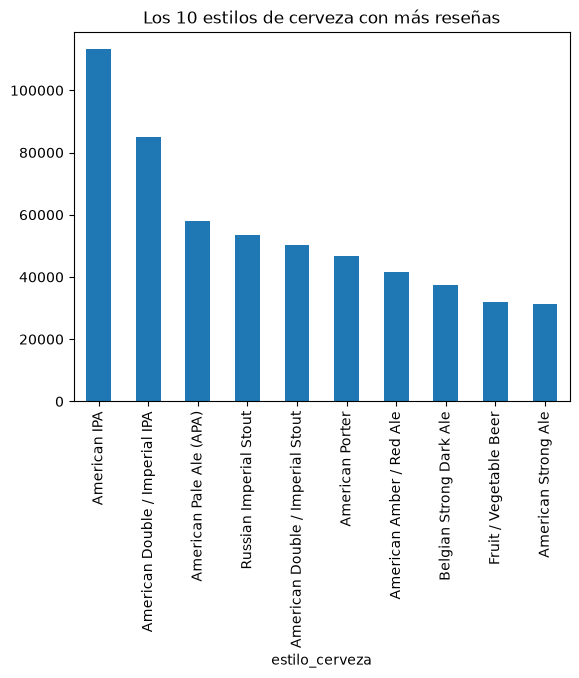

In [68]:
# Vamos a representar los 10 estilos de cerveza con más reseñas:
cervezas["estilo_cerveza"].value_counts().head(10).plot(kind="bar", title="Los 10 estilos de cerveza con más reseñas")

Lo que he visto y lo que he decidido:

Los estilos de cerveza no están representados por igual: American IPA concentra el mayor porcentaje de reseñas (7,45 %), seguido de American Double / Imperial IPA (5,60 %) y American Pale Ale (APA) (3,82 %). 
En total aparecen 104 estilos, con una presencia muy desigual entre ellos.
He decidido analizar los diez estilos más frecuentes en el gráfico para facilitar la comparación y conservar todos los estilos en el conjunto de datos, ya que los menos frecuentes también pueden ser relevantes para las recomendaciones de la aplicación.

## 7. ¿Cambia algo de un grupo a otro?

Aquí es donde suelen salir los hallazgos.

**7.1** Con groupby, calcula la media o la mediana de tu columna principal en cada grupo.

In [69]:
# Queremos investigar si la valoración general (rating) cambia según el estilo de cerveza (estilo_cerveza). 
# Empezamos identificando qué estilos reciben mejores puntuaciones, de mayor a menor

cervezas.groupby("estilo_cerveza")["rating"].mean().round(2).sort_values(ascending=False)

estilo_cerveza
American Wild Ale                   4.10
Gueuze                              4.09
Quadrupel (Quad)                    4.07
Lambic - Unblended                  4.06
American Double / Imperial Stout    4.03
                                    ... 
Happoshu                            2.91
Euro Strong Lager                   2.86
Light Lager                         2.69
American Malt Liquor                2.68
Low Alcohol Beer                    2.55
Name: rating, Length: 104, dtype: float64

**7.2** Haz otra comparación con otra columna de grupos.

In [70]:
# Investigamos si la valoración general (rating) cambia según la graduación alcohólica.
# Agrupamos las cervezas por intervalos de graduación para comparar sus valoraciones medias.

cervezas.groupby(pd.cut(cervezas["graduacion"], bins=[0, 5, 7, 9, 60], right=True))["rating"].mean().round(2)

graduacion
(0, 5]     3.58
(5, 7]     3.84
(7, 9]     3.93
(9, 60]    3.94
Name: rating, dtype: float64

**7.3** Antes de sacar conclusiones, mira cuántas filas tiene cada grupo. ¿Hay alguno con muy pocas?

In [71]:
# Contamos cuántas cervezas hay en cada intervalo de graduación.

# Ningún grupo tiene pocas obervaciones. Además, los cuatro grupos suman 1.518.829 reseñas, que coincide con el número de filas que tenemos después de eliminar las cervezas sin graduación.

print("Graduación hasta el 5 %:", len(cervezas[cervezas["graduacion"] <= 5]))

print("Graduación entre el 5 % y el 7 %:", len(cervezas[(cervezas["graduacion"] > 5) & (cervezas["graduacion"] <= 7)]))

print("Graduación entre el 7 % y el 9 %:", len(cervezas[(cervezas["graduacion"] > 7) & (cervezas["graduacion"] <= 9)]))

print("Graduación superior al 9 %:", len(cervezas[cervezas["graduacion"] > 9]))

Graduación hasta el 5 %: 313220
Graduación entre el 5 % y el 7 %: 597755
Graduación entre el 7 % y el 9 %: 334359
Graduación superior al 9 %: 273495


Lo que he visto y lo que he decidido:

Las valoraciones medias varían según el estilo de cerveza. Entre los estilos con mejores puntuaciones se encuentran American Wild Ale (4,10), Gueuze (4,09) y Quadrupel (4,07), mientras que Low Alcohol Beer obtiene una media de 2,55.

También se observa una relación entre la graduación alcohólica y la valoración media: las cervezas de hasta un 5 % obtienen una media de 3,58, frente a las de más de un 9 %, cuya media es de 3,94. Todos los grupos de graduación tienen un número elevado de reseñas, por lo que las comparaciones se basan en muchos datos.

Estos resultados sugieren que el estilo y la graduación pueden estar relacionados con la valoración que reciben las cervezas. Sin embargo, una graduación mayor no implica necesariamente una mejor valoración.

## 8. ¿Van juntas dos columnas?

Comprueba si dos columnas de números tienen relación.

**8.1** Calcula la correlación entre dos columnas de números.

In [72]:
cervezas["graduacion"].corr(cervezas["rating"])

np.float64(0.13851154361778928)

**8.2** Haz el gráfico de puntos de esas dos columnas.

<Axes: title={'center': 'Relación entre graduación y valoración'}, xlabel='graduacion', ylabel='rating'>

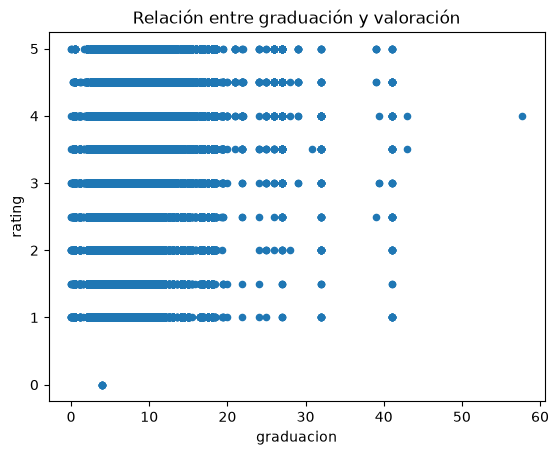

In [73]:
cervezas.plot(kind="scatter", x="graduacion", y="rating", title="Relación entre graduación y valoración")

Lo que he visto y lo que he decidido:

La correlación es de aproximadamente 0,14, lo que indica una relación positiva débil. 

Aunque las cervezas con mayor graduación tienden a recibir valoraciones algo superiores, el gráfico muestra que hay puntuaciones muy diferentes para graduaciones similares, por lo tanto, la graduación alcohólica por sí sola no explica la valoración de una cerveza.

## 9. ¿Qué he aprendido?

Las tres cosas que he podido descubrir tras realizar el EDA han sido:

1. Distribución de las valoraciones: la valoración general presenta una media de 3,82 y una mediana de 4 sobre 5. La proximidad entre ambas medidas indica que los valores centrales se sitúan en torno a puntuaciones altas.

2. Relación entre variables numéricas: la correlación de Pearson entre la graduación alcohólica y la valoración general es de 0,14, lo que indica una asociación lineal positiva débil. La graduación, por sí sola, no permite explicar las diferencias en las valoraciones.

3. Diferencias entre grupos: la valoración media aumenta de 3,58 en las cervezas de hasta un 5 % de alcohol a 3,94 en las de más del 9 %. Además, la valoración media varía según el estilo, desde 2,55 en Low Alcohol Beer hasta 4,10 en American Wild Ale.


En la limpieza de los datos he quitado tres columnas que no necesitaba para el análisis, he cambiado los nombres de las columnas al español y he eliminado las filas que no tenían información sobre la graduación alcohólica. 
Con estos cambios, el conjunto de datos ha pasado de 1.586.614 a 1.518.829 filas.

## 10. Guardar los datos limpios

**10.1** Guarda la tabla limpia en datos/datos_limpios.csv con to_csv y index=False. Es el archivo que lee la app.

In [75]:
cervezas.to_csv("datos/datos_limpios.csv", index=False)